# Del silbido al instrumento — Algoritmo Genético
**Inteligencia Artificial · Examen práctico EC02 · Grupo: _(nombres)_**

Notebook final reproducible (**Kernel → Restart & Run All**). Cada sección es de un rol:

| # | Sección | Rol | Módulo |
|---|---|---|---|
| 1 | Carga del silbido, pitch y tabla de genes | Rol 1 — Codificador | `src/rol1_codificacion.py` |
| 2 | Síntesis y fitness | Rol 2 — Traductor | `src/rol2_fitness.py` |
| 3 | Operadores genéticos | Rol 3 — Motor | `src/rol3_operadores.py` |
| 4 | Ciclo del AG y convergencia | Rol 4 — Estratega | `src/rol4_ag.py` |
| 5 | Resultado: audios | Rol 5 — Analista | `src/rol5_analisis.py` |
| 6 | Meta-evaluación | Rol 5 — Analista | `src/rol5_analisis.py` |

Los experimentos largos de cada rol están en `notebooks/` y sus resultados en `results/`.

In [1]:
import os, sys, importlib, time
RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, RAIZ); os.chdir(RAIZ)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, soundfile as sf
from IPython.display import Audio, display

from src import rol3_operadores as op, rol5_analisis as an

SEMILLA, SR = 42, 22050
an.entorno_reproducible(SEMILLA)
for c in ("results/audios", "results/graficos", "results/tablas"): os.makedirs(c, exist_ok=True)

def _cargar(nombre):
    try:
        return importlib.import_module(f"src.{nombre}"), True
    except ModuleNotFoundError:
        return importlib.import_module("src._provisional"), False

rol1, ok1 = _cargar("rol1_codificacion"); rol2, ok2 = _cargar("rol2_fitness"); rol4, ok4 = _cargar("rol4_ag")
if not (ok1 and ok2 and ok4):
    print("⚠️  USANDO MÓDULOS PROVISIONALES para:",
          [n for n, ok in (("Rol 1", ok1), ("Rol 2", ok2), ("Rol 4", ok4)) if not ok],
          "\n    → NO entregar así: cada rol debe subir su módulo con las firmas del README.")

python=3.13.16 | numpy=2.5.3 | scipy=1.18.1 | pandas=3.0.5 | matplotlib=3.11.2 | semilla=42
⚠️  USANDO MÓDULOS PROVISIONALES para: ['Rol 1', 'Rol 2', 'Rol 4'] 
    → NO entregar así: cada rol debe subir su módulo con las firmas del README.


## 1. Silbido, pitch y representación del cromosoma (Rol 1)

In [2]:
RUTA_SILBIDO = "data/silbido.wav"
if not os.path.exists(RUTA_SILBIDO):
    RUTA_SILBIDO = "data/silbido_prueba.wav"
    from src import _provisional; _provisional.crear_silbido_prueba(RUTA_SILBIDO)
    print("⚠️  Falta data/silbido.wav (grabación real); usando silbido sintético de prueba.")

TRANSPOSICION = -12
notas, durs = rol1.extraer_notas(RUTA_SILBIDO)
notas = [n + TRANSPOSICION for n in notas]
silbido, _ = sf.read(RUTA_SILBIDO)
print("Notas MIDI:", notas); print("Duraciones (s):", np.round(durs, 2))
display(Audio(silbido, rate=SR))

tabla_genes = pd.DataFrame(rol1.GENES, columns=["gen", "mín", "máx", "unidad"])
N_GENES = len(tabla_genes)
tabla_genes

⚠️  Falta data/silbido.wav (grabación real); usando silbido sintético de prueba.
Notas MIDI: [72, 74, 76, 77, 79]
Duraciones (s): [0.35 0.35 0.35 0.35 0.98]


,gen,mín,máx,unidad
0,amp_h1,0.000,1.00,lineal
1,amp_h2,0.000,1.00,lineal
2,amp_h3,0.000,1.00,lineal
3,amp_h4,0.000,1.00,lineal
4,amp_h5,0.000,1.00,lineal
5,amp_h6,0.000,1.00,lineal
6,amp_h7,0.000,1.00,lineal
7,amp_h8,0.000,1.00,lineal
8,ataque,0.005,0.30,s
9,decaimiento,0.020,1.00,s


In [3]:
# Test de la codificación: decodificar(codificar(x)) == x
x = np.random.default_rng(SEMILLA).random(N_GENES)
assert np.allclose(rol1.codificar(rol1.decodificar(x)), x), "codificar/decodificar no son inversas"
print("✔ codificar/decodificar son inversas")
# TODO Rol 1: análisis del tamaño del espacio de búsqueda + justificación de la codificación

✔ codificar/decodificar son inversas


## 2. Síntesis y función de fitness (Rol 2)

In [4]:
fitness = rol2.fitness
rng = np.random.default_rng(SEMILLA)
print("Fitness de 5 individuos aleatorios:", np.round([fitness(rng.random(N_GENES)) for _ in range(5)], 4))
# TODO Rol 2: referencia real, segunda métrica (croma), gráfico fitness vs variación de 1 gen

Fitness de 5 individuos aleatorios: [0.9573 0.9485 0.9616 0.9494 0.9529]


## 3. Operadores genéticos (Rol 3)

In [5]:
OPERADORES = op.COMBINACIONES["C3 Balance (torneo + blend α=0.5 + no-uniforme)"]   # ganadora (ver notebooks/rol3_rol5)
pd.read_csv("results/tablas/rol3_tabla_comparativa.csv", index_col=0) \
    if os.path.exists("results/tablas/rol3_tabla_comparativa.csv") else print("Correr notebooks/rol3_rol5_motor_y_analisis.ipynb")

,fitness_media,fitness_std,mejor,peor,gen_al_95,div_gen10,div_final
combinacion,,,,,,,
C3 Balance (torneo + blend α=0.5 + no-uniforme),0.9968,0.0023,0.9988,0.9931,35.6,0.4219,0.0199
C1 Explotación (torneo + blend α=0.3 + gaussiana σ=0.03),0.9932,0.0019,0.9952,0.9904,43.8,0.1372,0.0403
C2 Exploración (ruleta + uniforme + mut. uniforme),0.9928,0.0018,0.9949,0.9900,40.6,0.6942,0.6416


## 4. Ciclo del AG y convergencia (Rol 4)

Mejor fitness: 0.9954  (3.3 s)


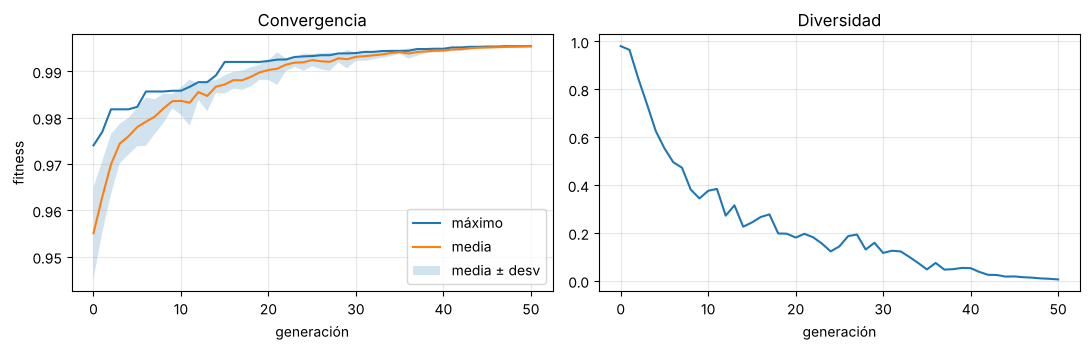

In [6]:
CONFIG = {"poblacion": 30, "n_genes": N_GENES, "generaciones": 50, "elitismo": 2, "operadores": OPERADORES}
t0 = time.time()
res = rol4.ejecutar_ag(CONFIG, fitness, SEMILLA)
h = res["historial"]
print(f"Mejor fitness: {res['mejor_fit']:.4f}  ({time.time()-t0:.1f} s)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
g = np.arange(len(h["max"]))
ax[0].plot(g, h["max"], label="máximo"); ax[0].plot(g, h["media"], label="media")
ax[0].fill_between(g, np.array(h["media"]) - h["std"], np.array(h["media"]) + h["std"], alpha=.2, label="media ± desv")
ax[0].set(title="Convergencia", xlabel="generación", ylabel="fitness"); ax[0].legend()
ax[1].plot(g, h["diversidad"]); ax[1].set(title="Diversidad", xlabel="generación")
for a in ax: a.grid(alpha=.3)
fig.tight_layout(); fig.savefig("results/graficos/final_convergencia.png", dpi=130)
# TODO Rol 4: tabla de 12+ configuraciones y análisis "¿qué hiperparámetro importa más?"

## 5. Resultado: la melodía tocada por el instrumento evolucionado (Rol 5)

**Silbido**

**Gen 0**

**Referencia**

**Mejor evolucionado**

,amp_h1,amp_h2,amp_h3,amp_h4,amp_h5,amp_h6,amp_h7,amp_h8,ataque,decaimiento,sostenido,liberacion,vib_frec,vib_prof
mejor gen (valores físicos),0.9992,0.942,0.5403,0.3607,0.1872,0.1177,0.0669,0.0331,0.0126,0.3634,0.1407,0.3596,0.4261,0.0


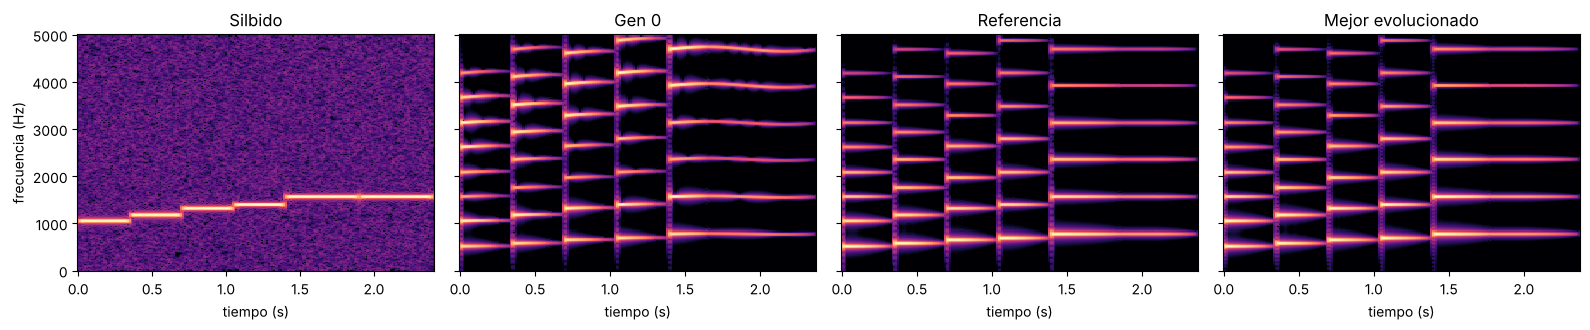

In [7]:
mejor_gen = rol1.decodificar(res["mejor"])
referencia = (rol2.sintetizar_instrumento(notas, durs, rol2.GEN_REFERENCIA) if hasattr(rol2, "GEN_REFERENCIA")
              else sf.read("data/referencia.wav")[0])
audios = {
    "Silbido": silbido,
    "Gen 0": rol2.sintetizar_instrumento(notas, durs, rol1.decodificar(res["mejor_gen0"])),
    "Referencia": referencia,
    "Mejor evolucionado": rol2.sintetizar_instrumento(notas, durs, mejor_gen),
}
for n, y in audios.items():
    sf.write(f"results/audios/{n.lower().replace(' ', '_')}.wav", 0.9 * y / np.max(np.abs(y)), SR, subtype="PCM_16")
an.comparacion_auditiva(audios, SR, "results/graficos")
pd.Series(mejor_gen).round(4).to_frame("mejor gen (valores físicos)").T

## 6. Meta-evaluación (Rol 5)

,n,media,desv,CV_%,min,mediana,max
10 semillas,10.0,0.99683,0.00178,0.17863,0.99313,0.99758,0.99881


,media_AG,media_aleatoria,mejora_%,U,p_valor,A12,AG_gana_en
AG vs aleatoria,0.996832,0.980997,1.614242,100.0,0.000091,1.0,10/10 semillas


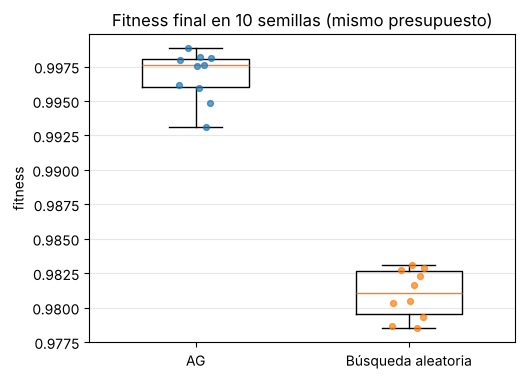

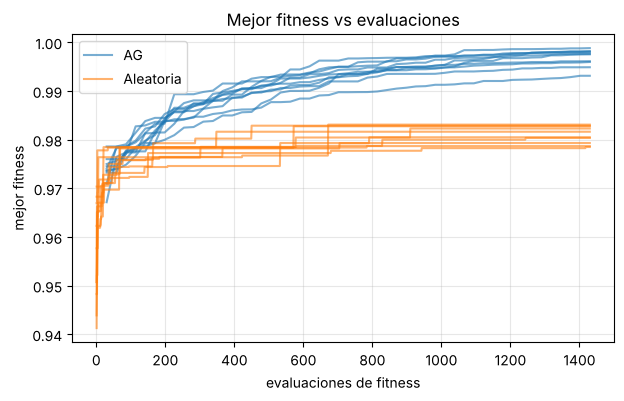

In [8]:
SEMILLAS = range(10)
df_sem, res_sem = an.corridas_semillas(rol4.ejecutar_ag, CONFIG, fitness, SEMILLAS)
df_base, prueba, curvas = an.ag_vs_aleatoria(res_sem, fitness, N_GENES, SEMILLAS)
display(an.resumen_varianza(df_sem).to_frame("10 semillas").T)
display(pd.Series(prueba).to_frame("AG vs aleatoria").T)
an.graficar_boxplot(df_base, "results/graficos"); an.graficar_curvas_vs_baseline(res_sem, curvas, "results/graficos");

**Tornado de hiperparámetros** (generado en `notebooks/rol3_rol5_motor_y_analisis.ipynb`)

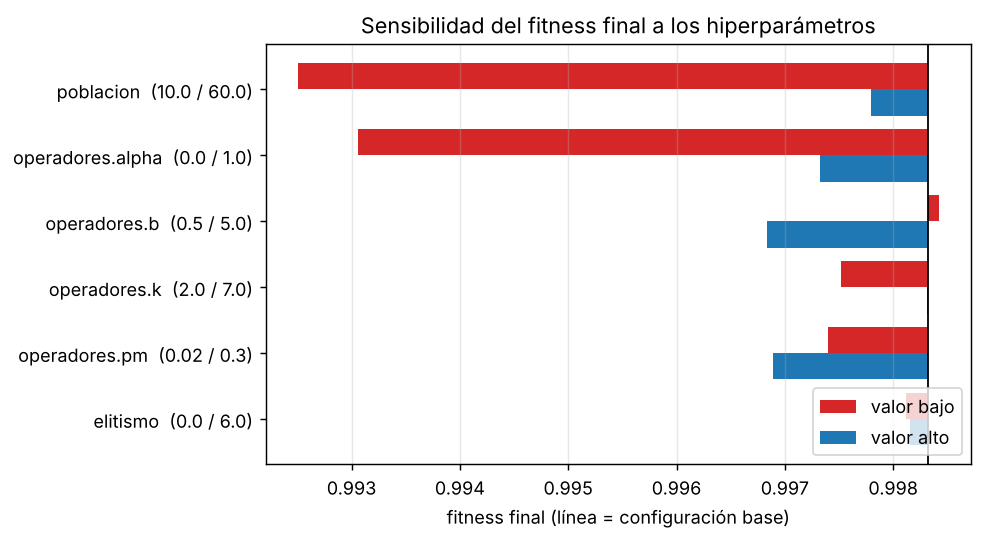

**Tornado de genes** (generado en `notebooks/rol3_rol5_motor_y_analisis.ipynb`)

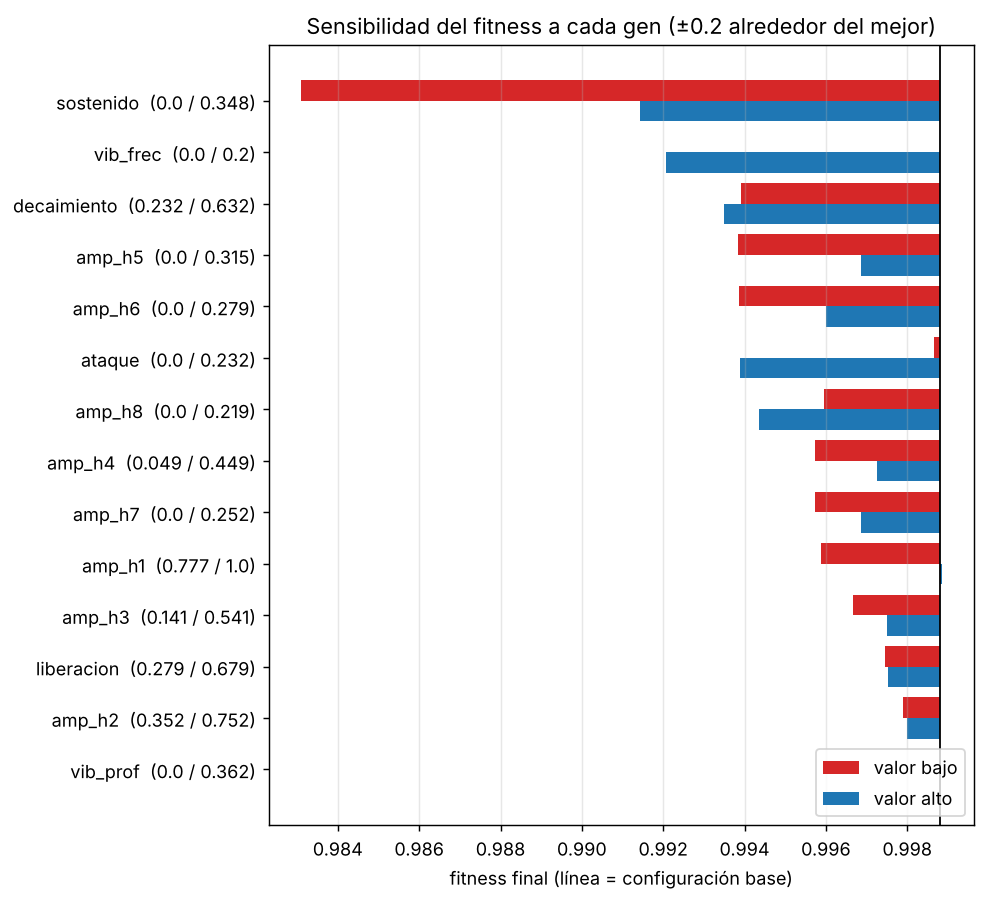

Encuesta aún sin respuestas: llena results/encuesta/respuestas.csv


In [9]:
for f, t in (("rol5_tornado_hiperparametros.png", "Tornado de hiperparámetros"), ("rol5_tornado_genes.png", "Tornado de genes")):
    ruta = f"results/graficos/{f}"
    if os.path.exists(ruta):
        from IPython.display import Image, Markdown
        display(Markdown(f"**{t}** (generado en `notebooks/rol3_rol5_motor_y_analisis.ipynb`)"), Image(ruta, width=650))
tabla_enc, conclusion = an.analizar_encuesta("results/encuesta", "piano") if os.path.exists("results/encuesta/clave.json") else (None, "Sin encuesta")
if tabla_enc is not None: display(tabla_enc)
print(conclusion)

## Conclusiones
_(Completar el Día 4 con los resultados finales de cada rol.)_